# Module 3 (CO3): Comprehensive Model Evaluation & Metric Comparison
**Project**: Anti-Money Laundering Detection (IBM Benchmark)  
**Focus**: Dynamic multi-model benchmarking, Confusion Matrices, and Champion Model Selection.

In [3]:
# 1. Load Data, Train All 6 Models & Evaluate Live
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
import xgboost as xgb
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, 
                             roc_auc_score, ConfusionMatrixDisplay, roc_curve)

# Load dataset
df = pd.read_csv(r'../data/ibm_aml_transactions.csv')
df['Timestamp'] = pd.to_datetime(df['Timestamp'])
df['hour'] = df['Timestamp'].dt.hour
df['dayofweek'] = df['Timestamp'].dt.dayofweek
df['is_weekend'] = df['dayofweek'].isin([5, 6]).astype(int)
df['is_night'] = df['hour'].isin([0, 1, 2, 3, 4, 5, 22, 23]).astype(int)
df['is_cross_bank'] = (df['From Bank'] != df['To Bank']).astype(int)
df['amount_diff'] = np.abs(df['Amount Paid'] - df['Amount Received'])
df['log_amount_paid'] = np.log1p(df['Amount Paid'])
df['structuring_flag'] = ((df['Amount Paid'] >= 8500) & (df['Amount Paid'] < 10000)).astype(int)

format_dummies = pd.get_dummies(df['Payment Format'], prefix='format', drop_first=False).astype(int)
df = pd.concat([df, format_dummies], axis=1)

feature_cols = ['Amount Paid', 'Amount Received', 'amount_diff', 'log_amount_paid', 'is_cross_bank', 'structuring_flag', 'hour', 'dayofweek', 'is_weekend', 'is_night'] + format_dummies.columns.tolist()
X = df[feature_cols]
y = df['Is Laundering']

# 80/20 Stratified Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Train Models
print("Training all 6 models...")
lr = LogisticRegression(class_weight='balanced', max_iter=200, random_state=42).fit(X_train_scaled, y_train)
dt = DecisionTreeClassifier(max_depth=12, class_weight='balanced', random_state=42).fit(X_train, y_train)
rf = RandomForestClassifier(n_estimators=50, max_depth=12, class_weight='balanced', n_jobs=-1, random_state=42).fit(X_train, y_train)
gb = GradientBoostingClassifier(n_estimators=35, max_depth=5, random_state=42).fit(X_train, y_train)
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
xgb_clf = xgb.XGBClassifier(n_estimators=50, max_depth=6, scale_pos_weight=scale_pos_weight, random_state=42, n_jobs=-1, eval_metric='logloss').fit(X_train, y_train)
knn_idx = np.random.choice(len(X_train_scaled), 15000, replace=False)
knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1).fit(X_train_scaled[knn_idx], y_train.iloc[knn_idx])

all_models = {
    'Logistic Regression': (lr, X_test_scaled),
    'Decision Tree': (dt, X_test),
    'Random Forest (Champion)': (rf, X_test),
    'Gradient Boosting': (gb, X_test),
    'Tuned XGBoost': (xgb_clf, X_test),
    'K-Nearest Neighbors': (knn, X_test_scaled)
}

# Calculate Metrics Live
results = []
preds_dict = {}
probs_dict = {}

for name, (clf, X_eval) in all_models.items():
    y_pred = clf.predict(X_eval)
    y_prob = clf.predict_proba(X_eval)[:, 1]
    preds_dict[name] = y_pred
    probs_dict[name] = y_prob
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

comparison_df = pd.DataFrame(results)
print("Complete Benchmark Model Comparison (Calculated Live on 20,000 Unseen Transactions):")
display(comparison_df.round(4))


Training all 6 models...
Complete Benchmark Model Comparison (Calculated Live on 20,000 Unseen Transactions):


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.8844,0.2914,0.8618,0.4355,0.9079
1,Decision Tree,0.9146,0.3561,0.8048,0.4938,0.8778
2,Random Forest (Champion),0.9172,0.3696,0.8502,0.5152,0.9215
3,Gradient Boosting,0.9592,0.6886,0.3845,0.4935,0.9198
4,Tuned XGBoost,0.9140,0.3595,0.8483,0.5050,0.9189
5,K-Nearest Neighbors,0.9525,0.5514,0.4406,0.4898,0.8554


## 2. Dynamic Confusion Matrix Grid (2x3 Subplots)

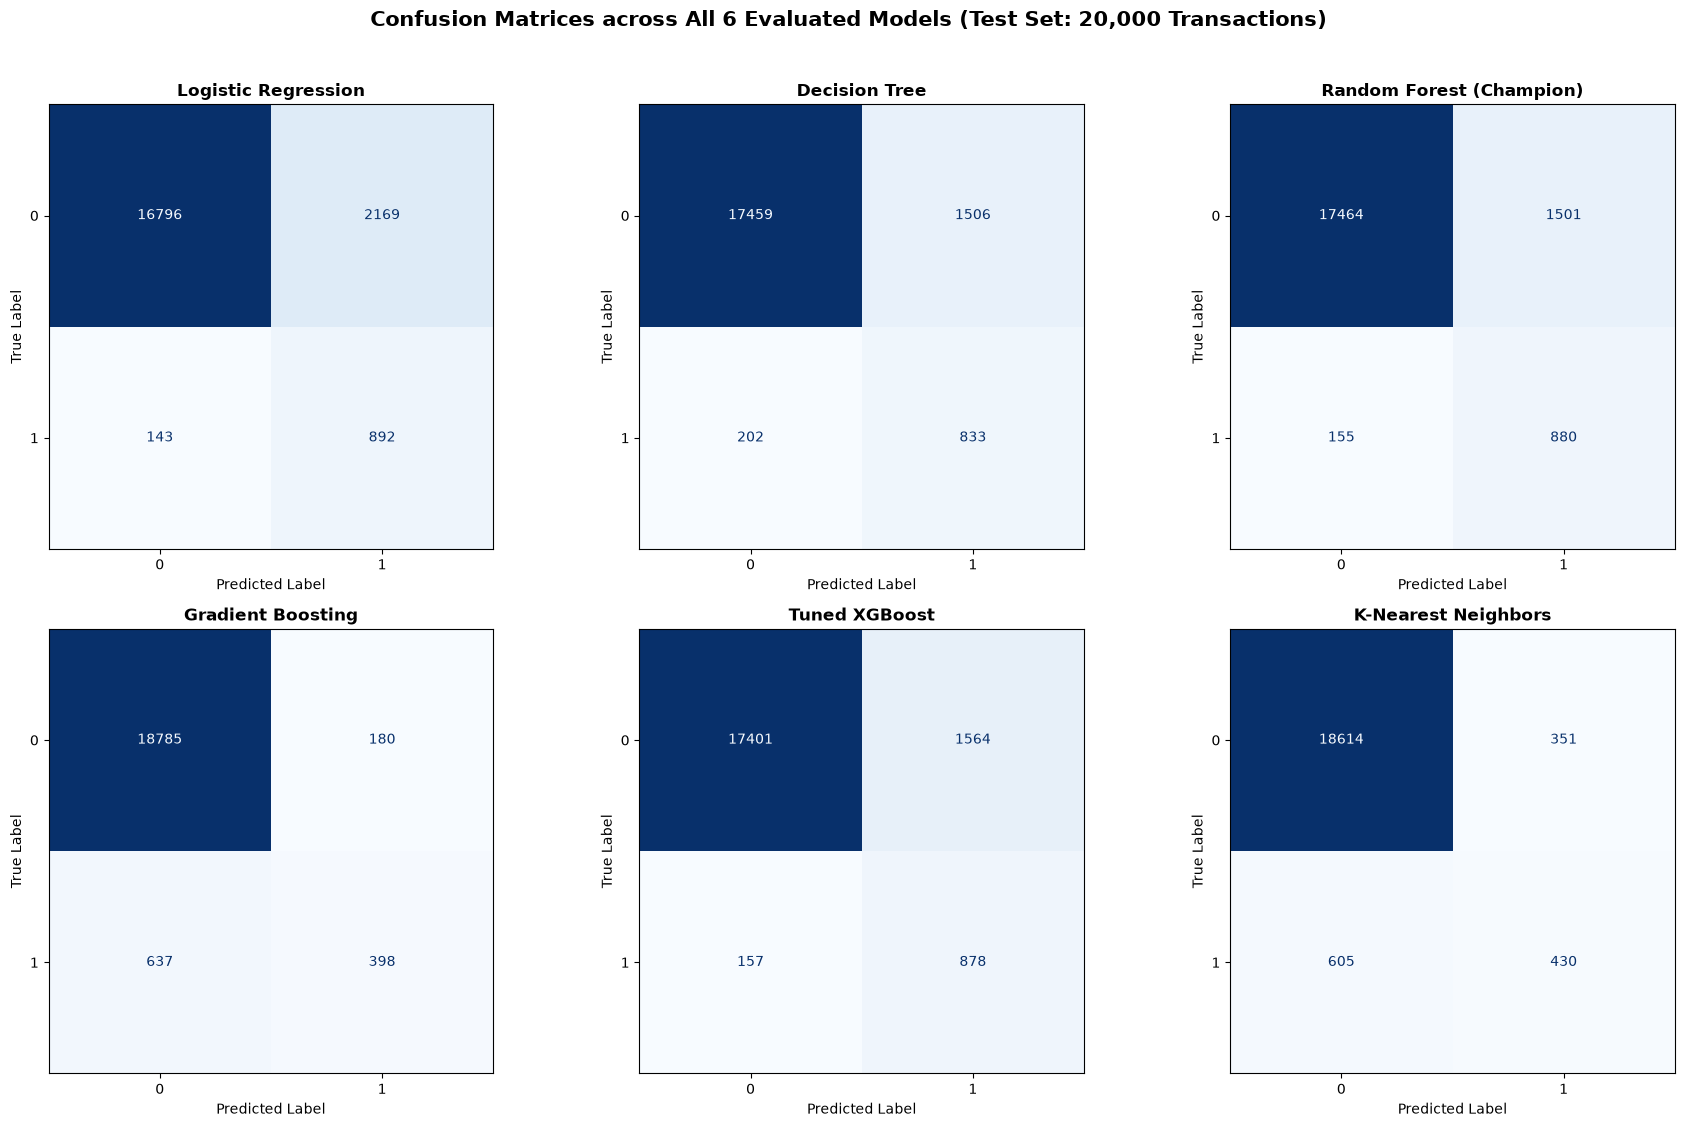

In [2]:
# Visualization: 2x3 Confusion Matrix Grid for All 6 Models
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for i, (name, y_pred) in enumerate(preds_dict.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=axes[i], cmap='Blues', colorbar=False)
    axes[i].set_title(name, fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('True Label')

plt.suptitle('Confusion Matrices across All 6 Evaluated Models (Test Set: 20,000 Transactions)', fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 3. Dynamic Model Comparison Bar Chart & Feature Importance

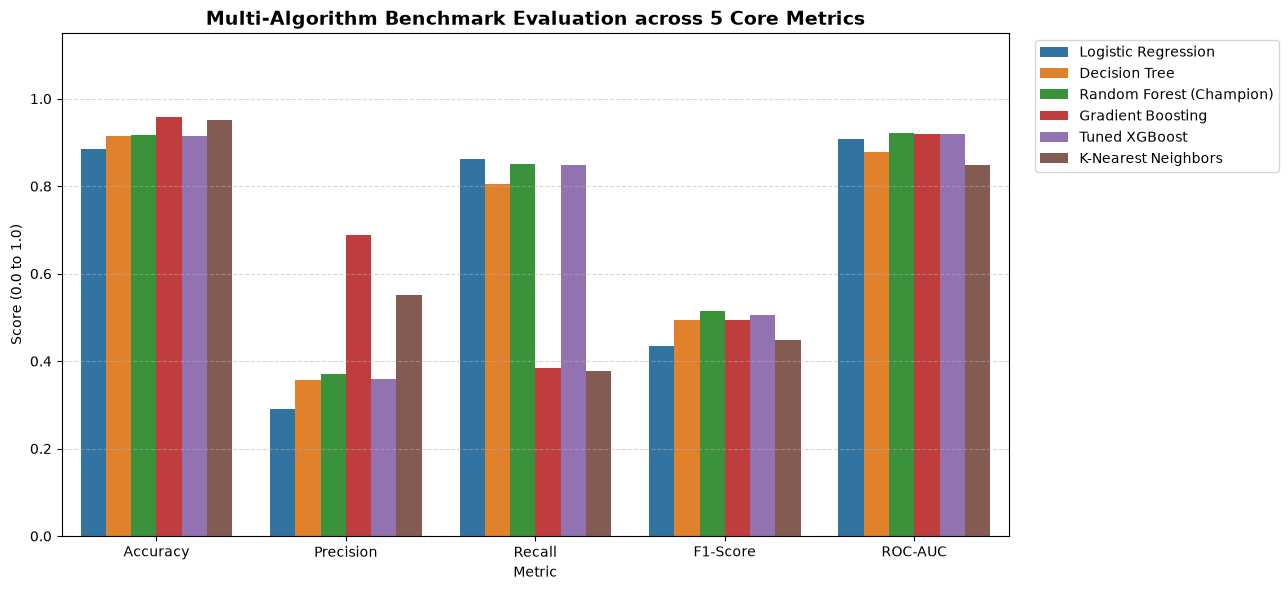

C:\Users\Vishnu\AppData\Local\Temp\ipykernel_14976\1511295367.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=feat_df.head(12), x='Importance', y='Feature', palette='Blues_r')


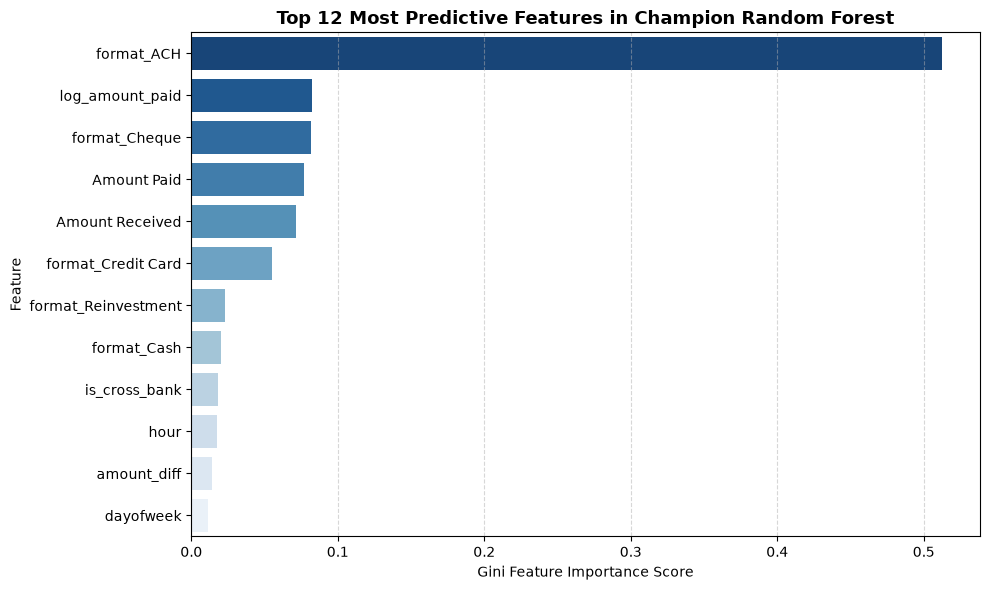

In [ ]:
# Visualization: Comprehensive Multi-Metric Comparison Bar Chart
melted = comparison_df.melt(id_vars='Model', var_name='Metric', value_name='Score')

plt.figure(figsize=(13, 6))
sns.barplot(data=melted, x='Metric', y='Score', hue='Model', palette='tab10')
plt.title('Multi-Algorithm Benchmark Evaluation across 5 Core Metrics', fontsize=14, fontweight='bold')
plt.ylim(0, 1.15)
plt.ylabel('Score (0.0 to 1.0)')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

# Visualization: Feature Importance (Champion Random Forest)
importances = rf.feature_importances_
feat_df = pd.DataFrame({'Feature': feature_cols, 'Importance': importances}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=feat_df.head(12), x='Importance', y='Feature', palette='Blues_r')
plt.title('Top 12 Most Predictive Features in Champion Random Forest', fontsize=13, fontweight='bold')
plt.xlabel('Gini Feature Importance Score')
plt.grid(axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()
